# 02. 데이터 정제 → 사람 분할 → A0 1회 학습 (전체 흐름 확인)
**9week · 2026-11-09** · 계획서: [연구계획서.md](연구계획서.md) 6절의 02

이 문서의 목적은 **좋은 성능을 내는 것이 아니라, 데이터가 모델까지 올바르게 흘러가는지 확인하는 것**이다.

| 단계 | 하는 일 | 왜 하는가 |
|---|---|---|
| 1 | 원본 읽기 | 00과 같은 규칙으로 레코드를 읽는다 |
| 2 | 정제 | 중복·가짜 0 레코드 삭제, 긴 공백에서 구간 끊기 (계획서 결정 1) |
| 3 | 남은 양 확인 | 행동·사람별로 데이터가 충분히 남았는지 확인 |
| 4 | 사람 분할 | 테스트 6명 + 개발 30명 5묶음을 확정 (계획서 결정 2) |
| 5 | 윈도우·표준화 | fold 0 기준으로 CNN 입력 `(128, 3)`을 만든다 |
| 6 | A0 1회 학습 | 기본 CNN이 학습되는지, 1회 학습 시간이 얼마인지 확인 |
| 7 | 결과 보기 | 행동별·사람별로 어디서 틀리는지 확인 |

이번 A0 점수는 **fold 1개 × seed 1개**의 결과라 모델 비교에 쓰지 않는다. 비교는 03부터 5 fold × 3 seed로 한다.

## 1. 설정과 원본 읽기
- 원본 압축파일을 직접 읽는다(압축 해제·수정 없음). Colab에서는 `ARCHIVE` 경로만 바꾸면 된다.
- 읽는 규칙은 00과 같다: 끝의 빈 필드 1개는 복구, 값이 빠진 레코드는 실패로 기록.
- 실패 레코드 자리에는 `None`을 넣어, 그 앞뒤가 하나의 연속 구간으로 이어지지 않게 한다.

In [1]:
import re, tarfile, time
import numpy as np
from collections import Counter

ARCHIVE = r"C:\Users\ektlaksskgodqhrgo\Downloads\WISDM_ar_latest.tar.gz"
ACTIVITIES = ['Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']
WIN = 128                       # 윈도우 길이 (샘플 128개 ≈ 6.4초)
TRAIN_STRIDE = 64               # 학습 윈도우 간격: 절반씩 겹침
EVAL_STRIDE = 128               # 검증·테스트 윈도우 간격: 겹치지 않음
MAX_GAP_NS = 1_000_000_000      # 1초(나노초) 넘는 공백에서 구간을 끊음

with tarfile.open(ARCHIVE) as tar:
    raw = tar.extractfile('WISDM_ar_v1.1/WISDM_ar_v1.1_raw.txt').read().decode()

records = []                    # (user, 행동번호, timestamp, x, y, z) 또는 None
for token in re.split(r'[;\r\n]+', raw):
    token = token.strip()
    if token == '':
        continue
    fields = token.split(',')
    if len(fields) == 7 and fields[-1].strip() == '':
        fields = fields[:6]                         # 끝 쉼표 복구
    try:
        if len(fields) != 6:
            raise ValueError
        records.append((int(fields[0]), ACTIVITIES.index(fields[1]), int(fields[2]),
                        float(fields[3]), float(fields[4]), float(fields[5])))
    except ValueError:
        records.append(None)                        # 파싱 실패 → 구간 경계

print('읽은 레코드:', len(records), '/ 파싱 실패:', records.count(None))

읽은 레코드: 1098209 / 파싱 실패: 1


## 2. 정제
계획서 2절의 정책 3을 그대로 적용한다.

| 순서 | 규칙 | 원본에서 확인한 이유 |
|---|---|---|
| ① | timestamp가 0인 레코드 삭제 | 가속도도 0,0,0인 가짜 값(아래에서 개수 확인) |
| ② | 이미 나온 것과 완전히 같은 레코드 삭제 | 인접 중복, 세션 통째 복사(사용자 19 Jogging) |
| ③ | 직전과 timestamp만 같고 값이 다른 레코드 삭제 | 같은 순간 두 번 기록. 소수(수백 건)라 첫 값만 남김 |
| ④ | 사용자·행동이 바뀌거나, 시간이 거꾸로 가거나, 1초 넘게 비면 구간을 끊음 | 서로 다른 순간이 한 윈도우에 붙지 않게 |

In [2]:
# ① timestamp 0 레코드가 정말 가짜(0,0,0)인지 먼저 확인
ts0 = [r for r in records if r is not None and r[2] == 0]
ts0_all_zero = sum(1 for r in ts0 if r[3] == 0 and r[4] == 0 and r[5] == 0)
print(f'timestamp=0 레코드 {len(ts0)}개 중 가속도가 0,0,0인 것: {ts0_all_zero}개')

# ①②③ 레코드 삭제
removed = Counter()
seen = set()
kept = []
for r in records:
    if r is None:
        kept.append(None)
        continue
    if r[2] == 0:
        removed['① timestamp 0'] += 1
        continue
    if r in seen:
        removed['② 완전 중복'] += 1
        continue
    seen.add(r)
    last = kept[-1] if kept else None
    if last is not None and last[:2] == r[:2] and last[2] == r[2]:
        removed['③ 같은 시각, 다른 값'] += 1
        continue
    kept.append(r)

# ④ 구간 나누기: 이어지지 않는 지점에서 끊는다
segments = []                   # (user, 행동번호, (L,3) 배열)
start = 0
for i in range(1, len(kept) + 1):
    a = kept[i - 1]
    b = kept[i] if i < len(kept) else None
    continuous = (a is not None and b is not None and a[:2] == b[:2]
                  and 0 < b[2] - a[2] <= MAX_GAP_NS)
    if not continuous:
        part = [r for r in kept[start:i] if r is not None]
        if part:
            segments.append((part[0][0], part[0][1],
                             np.array([r[3:] for r in part], dtype=np.float32)))
        start = i

usable = [s for s in segments if len(s[2]) >= WIN]      # 윈도우를 1개 이상 만들 수 있는 구간
for k, v in removed.items():
    print(f'{k:20s} 삭제 {v:6d}')
print('구간 수:', len(segments), '/ 128 이상인 구간:', len(usable))

timestamp=0 레코드 12845개 중 가속도가 0,0,0인 것: 12841개


② 완전 중복              삭제  54018
① timestamp 0        삭제  12845
③ 같은 시각, 다른 값        삭제    354
구간 수: 437 / 128 이상인 구간: 424


## 3. 정제 후 남은 양
- **유지율:** 원본 레코드 중 '128 이상 구간'에 들어가 실제로 쓰이는 비율.
- **윈도우 수:** 겹치지 않게(stride 128) 잘랐을 때의 개수 = 서로 다른 정보의 양. 구간 길이 L에서 `(L − 128) // 128 + 1`개.

In [3]:
def count_windows(length, stride):
    return (length - WIN) // stride + 1 if length >= WIN else 0

orig = Counter(r[1] for r in records if r is not None)
used = Counter()
wins = Counter()
for u, a, x in usable:
    used[a] += len(x)
    wins[a] += count_windows(len(x), EVAL_STRIDE)

print(f'{"행동":11s} {"원본":>8s} {"사용":>8s} {"유지율":>7s} {"윈도우":>6s}')
for a, name in enumerate(ACTIVITIES):
    print(f'{name:11s} {orig[a]:8d} {used[a]:8d} {used[a]/orig[a]*100:6.1f}% {wins[a]:6d}')
print(f'{"합계":11s} {sum(orig.values()):8d} {sum(used.values()):8d} '
      f'{sum(used.values())/sum(orig.values())*100:6.1f}% {sum(wins.values()):6d}')

행동                원본       사용     유지율    윈도우


Walking       424399   407295   96.0%   3146
Jogging       342179   302831   88.5%   2333
Upstairs      122869   118647   96.6%    867
Downstairs    100427    96994   96.6%    705
Sitting        59939    57216   95.5%    433
Standing       48395    47236   97.6%    357
합계           1098208  1030219   93.8%   7841


In [4]:
# 사람 × 행동 윈도우 수 (stride 128). 0은 그 사람에게 그 행동이 없다는 뜻
user_win = np.zeros((37, 6), dtype=int)          # 행 번호 = 사용자 ID (0번 행은 비움)
for u, a, x in usable:
    user_win[u, a] += count_windows(len(x), EVAL_STRIDE)

print('user ' + ' '.join(f'{n[:5]:>6s}' for n in ACTIVITIES) + '   합계')
for u in range(1, 37):
    print(f'{u:4d} ' + ' '.join(f'{v:6d}' for v in user_win[u]) + f' {user_win[u].sum():6d}')

user  Walki  Joggi  Upsta  Downs  Sitti  Stand   합계
   1     98     84     22     20      0      0    224
   2     90     90      0      0      0      0    180
   3     99     84     24     24     11     21    263
   4     46      6      9     12      9      0     82
   5     92     49     23     23     12     11    210
   6     92     75      7      7     12      5    198
   7     83     63     26     16     19     18    225
   8    130     77     31     24     20     25    307
   9     99      0      0      0      0      0     99
  10     99     92     32     28      0     12    263
  11     90     96     30     16      0      0    232
  12     81     93     17     19     16     12    238
  13    100     75     34     30      8     12    259
  14    106    101     62     22      0      0    291
  15     85     64     11      9      0      0    169
  16     84      0      8     10     21     14    137
  17     74     22     42     28      0      0    166
  18     96     70     17     

## 4. 사람 분할 (테스트 6명 + 개발 30명 5묶음)
**규칙** (성능을 보기 전에 정한 조건만 사용한다)
1. **테스트 6명**은 6개 행동을 모두 가진 사람 중에서 뽑는다. Macro F1은 6개 행동의 평균이므로, 행동이 빠지면 그 행동의 F1을 계산할 수 없다.
2. 나머지 30명을 6명씩 5묶음으로 나눈다. **각 묶음에 모든 행동의 보유자가 3명 이상** 있어야 한다. Sitting·Standing 평가가 사람 1~2명에 좌우되지 않게 하기 위해서다.
3. seed 0으로 무작위로 섞으며 처음으로 조건을 만족하는 분할을 쓴다. 결과 ID는 03 이후 그대로 복사해서 쓴다.

**한계:** 테스트가 '6개 행동을 모두 수행한 사람'으로만 이루어지므로, 일부 행동만 한 사람에 대한 성능은 개발 fold 결과로 본다.

In [5]:
has = user_win > 0
full_users = [u for u in range(1, 37) if has[u].all()]
print('6개 행동을 모두 가진 사람', len(full_users), '명:', full_users)

rng = np.random.RandomState(0)
for attempt in range(1, 100001):
    test_users = sorted(rng.choice(full_users, 6, replace=False).tolist())
    dev_users = [u for u in range(1, 37) if u not in test_users]
    rng.shuffle(dev_users)
    groups = [sorted(dev_users[i * 6:(i + 1) * 6]) for i in range(5)]
    if all(has[g].sum(axis=0).min() >= 3 for g in groups):
        break
print('조건을 만족한 시도 번호:', attempt)

def show_group(name, users):
    w = user_win[users].sum(axis=0)
    h = has[users].sum(axis=0)
    print(f'{name:7s} {str(users):26s} ' + ' '.join(f'{wi:4d}({hi})' for wi, hi in zip(w, h)))

print('\n' + ' ' * 35 + '  '.join(f'{n[:7]:>7s}' for n in ACTIVITIES))
print(' ' * 35 + '윈도우 수(보유자 수)')
show_group('TEST', test_users)
for i, g in enumerate(groups):
    show_group(f'fold {i}', g)

6개 행동을 모두 가진 사람 19 명: [3, 5, 6, 7, 8, 12, 13, 18, 19, 20, 21, 24, 27, 29, 31, 32, 33, 34, 36]
조건을 만족한 시도 번호: 10

                                   Walking  Jogging  Upstair  Downsta  Sitting  Standin
                                   윈도우 수(보유자 수)
TEST    [6, 21, 24, 27, 29, 34]     518(6)  483(6)  145(6)  130(6)   71(6)   64(6)
fold 0  [1, 7, 20, 22, 25, 36]      429(6)  397(6)  160(5)  126(5)  155(3)   73(3)
fold 1  [9, 16, 19, 26, 28, 33]     596(6)  186(3)  103(5)  111(5)   62(3)   51(4)
fold 2  [2, 3, 4, 14, 30, 31]       558(6)  389(5)  160(5)  115(5)   46(4)   64(3)
fold 3  [8, 10, 11, 12, 13, 15]     585(6)  497(6)  155(6)  126(6)   44(3)   61(4)
fold 4  [5, 17, 18, 23, 32, 35]     460(6)  381(6)  144(5)   97(5)   55(4)   44(4)


## 5. fold 0의 윈도우 만들기와 표준화
- **fold 0:** 묶음 0의 6명이 검증, 나머지 24명이 학습. 테스트 6명은 여기서 쓰지 않는다.
- **표준화:** 학습 사람들의 정제된 원본 샘플로 축별 평균·표준편차를 계산한 뒤, 검증에도 같은 값을 적용한다. 검증 데이터의 정보가 학습에 새지 않게 하기 위해서다.
- **윈도우:** 구간 안에서만 자른다. 학습은 stride 64(절반 겹침), 검증은 stride 128(겹치지 않음).

In [6]:
FOLD = 0
val_users = groups[FOLD]
train_users = sorted(u for i, g in enumerate(groups) if i != FOLD for u in g)

train_samples = np.concatenate([x for u, a, x in usable if u in train_users])
mean = train_samples.mean(axis=0)
std = train_samples.std(axis=0)
print('학습 사람 수:', len(train_users), '/ 검증 사람:', val_users)
print('축별 평균:', mean.round(3), '/ 표준편차:', std.round(3))

def make_windows(users, stride):
    X, y, who = [], [], []
    for u, a, x in usable:
        if u not in users:
            continue
        x = (x - mean) / std
        for s in range(0, len(x) - WIN + 1, stride):
            X.append(x[s:s + WIN])
            y.append(a)
            who.append(u)
    return np.array(X, dtype=np.float32), np.array(y), np.array(who)

X_train, y_train, u_train = make_windows(train_users, TRAIN_STRIDE)
X_val, y_val, u_val = make_windows(val_users, EVAL_STRIDE)
print('X_train', X_train.shape, '/ X_val', X_val.shape)
print('학습 윈도우 행동별:', np.bincount(y_train, minlength=6))
print('검증 윈도우 행동별:', np.bincount(y_val, minlength=6))

학습 사람 수: 24 / 검증 사람: [1, 7, 20, 22, 25, 36]
축별 평균: [0.645 7.61  0.176] / 표준편차: [6.785 6.412 4.828]


X_train (10041, 128, 3) / X_val (1340, 128, 3)
학습 윈도우 행동별: [4375 2890 1080  850  411  435]
검증 윈도우 행동별: [429 397 160 126 155  73]


## 6. A0 기본 CNN과 학습
**A0 구조:** 01의 정의(“A1 = 같은 기본 CNN + residual shortcut”)를 따른다. A1에서 shortcut만 더할 수 있도록, A0를 **두 번의 합성곱으로 된 블록 2개**로 만든다.

```text
입력 (128,3)
→ stem: Conv1D(64, k5) → BN → ReLU
→ 블록 1: [Conv1D(64,k5) → BN → ReLU → Conv1D(64,k5) → BN] → ReLU → MaxPool(2)
→ 블록 2: [같은 구성] → ReLU → MaxPool(2)
→ GlobalAveragePooling1D → Dropout(0.4) → Dense(6, softmax)
```
A1에서는 대괄호 `[ ]` 부분의 출력에 블록 입력을 더하는 것(Add)만 바뀐다.

**학습 설정** (01의 16절 그대로)

| 항목 | 값 |
|---|---|
| optimizer | Adam, lr 0.001 |
| batch, 최대 epoch | 64, 100 |
| 손실 | 가중치 없는 cross-entropy |
| 조기 종료 | 검증 Macro F1이 12 epoch 동안 개선되지 않으면 종료, 가장 좋았던 가중치로 복원 |
| seed | 0 |

Keras에는 Macro F1로 조기 종료하는 기능이 없다. 그래서 `ValMacroF1` 콜백이 매 epoch 검증 Macro F1을 계산해 기록하고, 기본 `EarlyStopping`이 그 값을 기준으로 멈춘다.

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import f1_score, classification_report, confusion_matrix

tf.keras.utils.set_random_seed(0)

def conv_bn(x, filters, relu=True):
    x = layers.Conv1D(filters, 5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x) if relu else x

inputs = layers.Input(shape=(WIN, 3))
x = conv_bn(inputs, 64)                         # stem
for block in range(2):
    h = conv_bn(x, 64)
    h = conv_bn(h, 64, relu=False)
    x = layers.ReLU()(h)                        # A1에서는 여기가 ReLU(h + x)
    x = layers.MaxPooling1D(2)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(6, activation='softmax')(x)
model = models.Model(inputs, outputs, name='A0')

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('파라미터 수:', model.count_params())

파라미터 수: 84870


In [8]:
class ValMacroF1(tf.keras.callbacks.Callback):
    # 매 epoch 끝에 검증 Macro F1을 계산해 logs에 넣는다 → EarlyStopping이 이 값을 본다
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(X_val, verbose=0).argmax(axis=1)
        logs['val_macro_f1'] = f1_score(y_val, pred, average='macro')

early = tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=12,
                                         restore_best_weights=True)
start_time = time.time()
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=100, batch_size=64, callbacks=[ValMacroF1(), early], verbose=2)
train_seconds = time.time() - start_time

f1_curve = history.history['val_macro_f1']
best_epoch = int(np.argmax(f1_curve)) + 1
print(f'\n학습 시간 {train_seconds:.0f}초 / 실행 epoch {len(f1_curve)} / 최고 epoch {best_epoch}')

Epoch 1/100


157/157 - 31s - 200ms/step - accuracy: 0.8796 - loss: 0.3627 - val_accuracy: 0.2955 - val_loss: 1.8469 - val_macro_f1: 0.2836


Epoch 2/100


157/157 - 6s - 41ms/step - accuracy: 0.9742 - loss: 0.0978 - val_accuracy: 0.8254 - val_loss: 0.5931 - val_macro_f1: 0.7980


Epoch 3/100


157/157 - 6s - 41ms/step - accuracy: 0.9852 - loss: 0.0595 - val_accuracy: 0.8881 - val_loss: 0.5571 - val_macro_f1: 0.8720


... (47 outputs left out)

157/157 - 6s - 37ms/step - accuracy: 0.9996 - loss: 0.0022 - val_accuracy: 0.9052 - val_loss: 0.6963 - val_macro_f1: 0.9026


Epoch 28/100


157/157 - 6s - 38ms/step - accuracy: 0.9987 - loss: 0.0046 - val_accuracy: 0.8575 - val_loss: 1.3312 - val_macro_f1: 0.8668



학습 시간 200초 / 실행 epoch 28 / 최고 epoch 16


## 7. 결과: 어디서 맞히고 어디서 틀리는가
- **전체:** Accuracy, Macro F1
- **행동별:** precision(그 행동이라고 답한 것 중 맞은 비율), recall(그 행동 중 맞힌 비율)
- **혼동행렬:** 행 = 정답, 열 = 예측
- **사람별:** 검증 6명 각각의 정확도. 평균이 일부 사람의 실패를 가리지 않는지 확인

In [9]:
pred = model.predict(X_val, verbose=0).argmax(axis=1)
print(f'검증 Accuracy {np.mean(pred == y_val):.4f} / Macro F1 {f1_score(y_val, pred, average="macro"):.4f}\n')
print(classification_report(y_val, pred, labels=range(6), target_names=ACTIVITIES, digits=3, zero_division=0))

cm = confusion_matrix(y_val, pred, labels=range(6))
print('혼동행렬 (행=정답, 열=예측)')
print(' ' * 11 + ''.join(f'{n[:6]:>8s}' for n in ACTIVITIES))
for a, name in enumerate(ACTIVITIES):
    print(f'{name:11s}' + ''.join(f'{v:8d}' for v in cm[a]))

검증 Accuracy 0.9157 / Macro F1 0.9125

              precision    recall  f1-score   support

     Walking      0.942     0.874     0.907       429
     Jogging      0.945     0.950     0.947       397
    Upstairs      0.956     0.819     0.882       160
  Downstairs      0.686     0.952     0.797       126
     Sitting      1.000     0.974     0.987       155
    Standing      0.912     1.000     0.954        73

    accuracy                          0.916      1340
   macro avg      0.907     0.928     0.912      1340
weighted avg      0.926     0.916     0.917      1340

혼동행렬 (행=정답, 열=예측)
             Walkin  Joggin  Upstai  Downst  Sittin  Standi
Walking         375       0       0      54       0       0
Jogging          19     377       0       1       0       0
Upstairs          4      22     131       0       0       3
Downstairs        0       0       6     120       0       0
Sitting           0       0       0       0     151       4
Standing          0       0       0      

In [10]:
print('사람별 결과 (검증 6명)')
for u in val_users:
    m = u_val == u
    acts = sorted(set(y_val[m]))
    wrong = Counter((ACTIVITIES[t][:4] + '→' + ACTIVITIES[p][:4])
                    for t, p in zip(y_val[m], pred[m]) if t != p)
    print(f'user {u:2d}: 윈도우 {m.sum():4d}, 정확도 {np.mean(pred[m] == y_val[m]):.3f}, '
          f'행동 {len(acts)}개, 주요 오류 {wrong.most_common(3)}')

사람별 결과 (검증 6명)
user  1: 윈도우  224, 정확도 0.902, 행동 4개, 주요 오류 [('Upst→Jogg', 22)]
user  7: 윈도우  225, 정확도 0.960, 행동 6개, 주요 오류 [('Down→Upst', 5), ('Upst→Walk', 4)]
user 20: 윈도우  384, 정확도 0.987, 행동 6개, 주요 오류 [('Sitt→Stan', 4), ('Walk→Down', 1)]
user 22: 윈도우  169, 정확도 0.994, 행동 4개, 주요 오류 [('Down→Upst', 1)]
user 25: 윈도우  103, 정확도 0.408, 행동 2개, 주요 오류 [('Walk→Down', 53), ('Jogg→Walk', 8)]
user 36: 윈도우  235, 정확도 0.936, 행동 6개, 주요 오류 [('Jogg→Walk', 11), ('Upst→Stan', 3), ('Jogg→Down', 1)]


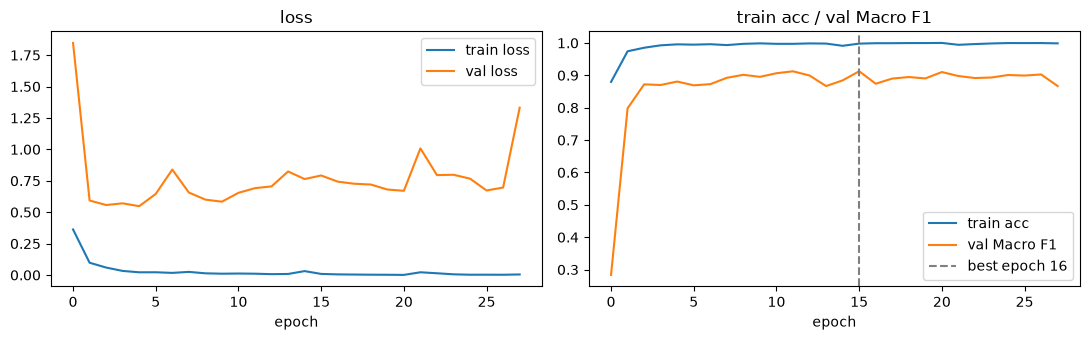

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history['loss'], label='train loss')
ax[0].plot(history.history['val_loss'], label='val loss')
ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].set_title('loss')
ax[1].plot(history.history['accuracy'], label='train acc')
ax[1].plot(f1_curve, label='val Macro F1')
ax[1].axvline(best_epoch - 1, color='gray', ls='--', label=f'best epoch {best_epoch}')
ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('train acc / val Macro F1')
plt.tight_layout(); plt.show()


## 8. 결과 해석 (2026-11-09 로컬 CPU 실행)

### 8-1. 흐름 확인: 성공
원본 → 정제 → 분할 → 윈도우 → 학습 → 평가까지 오류 없이 연결되었다. 검증 결과는 Accuracy **0.916**, Macro F1 **0.912**다. **fold 1개 × seed 1개의 결과이므로 모델 비교에 쓰지 않는다.**

### 8-2. 정제: 원본의 93.8%를 사용, 윈도우 7,841개
- timestamp 0 레코드 12,845개 중 **12,841개가 가속도 0,0,0**이었다. 가짜 기록이라는 판단이 맞았다.
- 정제 후 구간은 437개뿐이다. 데이터 대부분이 끊김 없는 긴 구간에 들어 있다는 뜻이다.
- 계획서의 시뮬레이션(7,680개)보다 윈도우가 조금 많다. '같은 시각, 다른 값'(354건)을 구간을 끊지 않고 삭제하도록 바꿨기 때문이다.
- Sitting 433개, Standing 357개로 여전히 가장 적다.

### 8-3. 사람 한 명이 점수를 얼마나 움직이는가: 실제로 확인됨
| 검증 사람 | 정확도 | 주요 오류 |
|---|---:|---|
| 20 | 0.987 | |
| 22 | 0.994 | |
| 7 | 0.960 | |
| 36 | 0.936 | |
| 1 | 0.902 | Upstairs → Jogging 22개 |
| **25** | **0.408** | **Walking 53개 전부 → Downstairs** |

- 전체 오류 113개 중 61개가 사용자 25 한 명에게서 나왔다.
- 사용자 25를 빼고 계산하면 Accuracy는 0.916 → **약 0.958**로, 한 사람이 약 4%p를 움직인다.
- Downstairs precision이 0.686으로 낮은 것도 대부분 이 사람 때문이다.
- 계획서에서 걱정한 "사람 1~2명에 점수가 좌우되는 문제"가 실제로 나타났다. 교차검증이 필요한 이유를 보여준다.

### 8-4. 학습 곡선: 빠른 과적합, epoch마다 흔들리는 검증 점수
- 학습 정확도는 3~5 epoch 만에 0.99 이상이 된다. 검증 loss는 5 epoch 이후 오히려 증가한다.
- 검증 Macro F1은 이웃한 epoch 사이에서도 0.867~0.913으로 오르내린다(예: 16 epoch 0.913 → 17 epoch 0.874).
- 조기 종료는 이 흔들림 중 가장 높은 지점을 고른다. 그래서 한 번의 학습 결과는 약간 낙관적이다.
- 결론: 1%p 정도의 모델 차이는 한 번의 학습으로 판정할 수 없다. 계획서의 5 fold × 3 seed 반복과 같은 fold끼리의 비교가 필요하다.

### 8-5. 학습 시간
- 1회 약 200초(28 epoch, CPU 16코어)가 걸렸다.
- 1단계 105회 × 약 200초 ≈ **약 6시간**이다. B 계열은 모델이 더 커서 더 오래 걸린다.
- 로컬 CPU로 밤새 돌릴지 Colab GPU를 쓸지 정해야 한다.

## 9. 다음 단계 전에 확인할 것
1. **사용자 20의 Sitting 윈도우 118개 → 확인 완료: 실제로 오래 측정한 것.** 원본 15,644개 레코드가 약 782초(13분) 동안 1초 넘는 공백 없이 이어지고, 20개 샘플 단위로 반복되는 패턴도 없다. 복사가 아니므로 삭제하지 않는다.
   - 영향: fold 0 검증의 Sitting 155개 중 118개가 이 사람이라, fold 0의 Sitting 점수는 사실상 사용자 20 한 명의 점수다. 사용자 20이 학습에 들어가는 fold에서는 Sitting 학습 데이터의 약 1/4을 한 사람이 차지한다.
   - 대응: 지금은 바꾸지 않는다(데이터 고정 원칙). 사람별 윈도우 수 상한 같은 처리는 구조 비교가 끝난 뒤 별도 실험 후보로 기록한다.
2. **사용자 25의 Walking:** 개발 데이터이므로 원본을 살펴봐도 된다. 휴대폰 방향 등 신호 특징을 확인하면 구조로 풀 수 있는 문제인지, 데이터 자체의 문제인지 구분할 수 있다.
3. **분할 확정 (03 이후 그대로 복사해서 사용):**
   - TEST = [6, 21, 24, 27, 29, 34]
   - fold 0 = [1, 7, 20, 22, 25, 36]
   - fold 1 = [9, 16, 19, 26, 28, 33]
   - fold 2 = [2, 3, 4, 14, 30, 31]
   - fold 3 = [8, 10, 11, 12, 13, 15]
   - fold 4 = [5, 17, 18, 23, 32, 35]
4. 계획서 결정 3(판정 최소 차이)·4(경량화 허용폭)를 정한 뒤 **03: A0·A1·A2 × 5 fold × 3 seed**로 넘어간다.
